In [ ]:
# CELL 1 — Install & Import Libraries

# ==============================
# 📦 Install required libraries
# ==============================
!pip install pandas numpy matplotlib scikit-learn imbalanced-learn tensorflow --quiet

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report
from sklearn.preprocessing import MinMaxScaler
from imblearn.over_sampling import SMOTE
import tensorflow as tf

In [ ]:
# CELL 2 — Upload Landslide Dataset

from google.colab import files
uploaded = files.upload()


Saving landslide_data.csv to landslide_data.csv


In [ ]:
# CELL 3 — Load & Inspect Data

# CELL 3 — Load & Inspect Data

df = pd.read_csv("landslide_data.csv")

# Handle missing values only for numeric columns (fill with mean for numeric columns)
numeric_cols = df.select_dtypes(include=[np.number]).columns  # Get numeric columns
df[numeric_cols] = df[numeric_cols].fillna(df[numeric_cols].mean())  # Fill missing values with the mean of each column

# Encode categorical columns if necessary (e.g., map 'Low', 'Medium', 'High' to numeric)
df['risk_level'] = df['risk_level'].map({'Low': 0, 'Medium': 1, 'High': 2, 'Critical': 2})

# Select features
X = df[['pressure', 'soil_moisture']]  # Example features
y = df['risk_level']

# Normalize features using MinMaxScaler
scaler = MinMaxScaler()
X_scaled = scaler.fit_transform(X)

# Check the cleaned data
print(df.head())  # This will print the first 5 rows to ensure the preprocessing worked


             timestamp  pressure  soil_moisture landslide_detected  risk_level
0  2026-02-18 17:04:08       429           2416                 No           0
1              Unknown       417           2384                 No           0
2  2026-02-18 17:04:27       446           2406                 No           0
3  2026-02-18 17:04:31       433           2413                 No           0
4  2026-02-18 17:04:36       432           2413                 No           0


In [ ]:
# CELL 4 — Handle Class Imbalance using SMOTE

smote = SMOTE(sampling_strategy='auto', random_state=42)
X_res, y_res = smote.fit_resample(X_scaled, y)

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(X_res, y_res, test_size=0.2, random_state=42)


In [ ]:
# CELL 5 — Build Random Forest Model

rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)


RandomForestClassifier(random_state=42)

✅ Landslide Detection Accuracy: 78.93 %


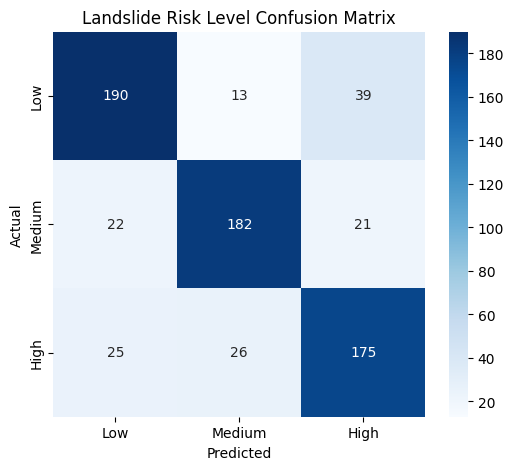

Landslide Detection Classification Report
              precision    recall  f1-score   support

         Low       0.80      0.79      0.79       242
      Medium       0.82      0.81      0.82       225
        High       0.74      0.77      0.76       226

    accuracy                           0.79       693
   macro avg       0.79      0.79      0.79       693
weighted avg       0.79      0.79      0.79       693



In [ ]:
# CELL 6 — Model Evaluation

# Predictions
y_pred = rf_model.predict(X_test)

# Accuracy Score
acc = accuracy_score(y_test, y_pred)
print("✅ Landslide Detection Accuracy:", round(acc * 100, 2), "%")

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=["Low", "Medium", "High"], yticklabels=["Low", "Medium", "High"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Landslide Risk Level Confusion Matrix")
plt.show()

# Classification Report
print("Landslide Detection Classification Report")
print(classification_report(y_test, y_pred, labels=[0, 1, 2], target_names=["Low", "Medium", "High"], zero_division=0))



In [ ]:
# CELL 7 — Save Random Forest Model

import joblib
joblib.dump(rf_model, 'landslide_rf_model.pkl')
print("✅ Landslide Random Forest model saved as .pkl")

✅ Landslide Random Forest model saved as .pkl


In [ ]:
# -----------------------------
# CELL 8 — Full 3-Layer NN for TFLite
# -----------------------------

import tensorflow as tf

# Build a proper 3-layer NN
model = tf.keras.Sequential([
    tf.keras.layers.InputLayer(input_shape=(X_train.shape[1],)),  # Input shape = number of features
    tf.keras.layers.Dense(64, activation='relu'),                 # Layer 1
    tf.keras.layers.Dense(32, activation='relu'),                 # Layer 2
    tf.keras.layers.Dense(3, activation='softmax')                # Output layer (Low, Medium, High)
])

# Compile the model
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Train the model
history = model.fit(
    X_train, y_train,
    epochs=30,                 # More epochs than before
    batch_size=16,             # Smaller batch size for better learning
    validation_split=0.1,
    callbacks=[tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)]
)

# -----------------------------
# Convert to TFLite
# -----------------------------

converter = tf.lite.TFLiteConverter.from_keras_model(model)
converter.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS]  # Pure TFLite ops
converter._experimental_lower_tensor_list_ops = True
converter.experimental_enable_resource_variables = False
converter.optimizations = [tf.lite.Optimize.DEFAULT]

tflite_model = converter.convert()

# Save TFLite model
with open("landslide_detection_model.tflite", "wb") as f:
    f.write(tflite_model)

print("✅ Landslide Detection TFLite model (3-layer NN) created")


Epoch 1/30


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/input_layer.py:27: UserWarning: Argument `input_shape` is deprecated. Use `shape` instead.
  warnings.warn(


156/156 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.3459 - loss: 1.0776 - val_accuracy: 0.3058 - val_loss: 1.0308
Epoch 2/30
156/156 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.4715 - loss: 1.0037 - val_accuracy: 0.4784 - val_loss: 0.9563
Epoch 3/30
156/156 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.5483 - loss: 0.9259 - val_accuracy: 0.6547 - val_loss: 0.8751
Epoch 4/30
156/156 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.6454 - loss: 0.8443 - val_accuracy: 0.6403 - val_loss: 0.8316
Epoch 5/30
156/156 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.6311 - loss: 0.8166 - val_accuracy: 0.6655 - val_loss: 0.8000
Epoch 6/30
156/156 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.6423 - loss: 0.8046 - val_accuracy: 0.6475 - val_loss: 0.8064
Epoch 7/30
156/156 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - accuracy: 0.6495 - loss: 0.7858 - val_accuracy: 0.6691 - val_loss: 0.7773
Epoch 8/30
156/156 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - accuracy: 0.6370 - loss: 0.7676 - val_accuracy: 0.6763 - va

In [ ]:
# -----------------------------
# CELL 9 — Download TFLite Model
# -----------------------------
from google.colab import files
files.download("landslide_detection_model.tflite")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>